# [LAB-06] 데이터 시각화

## 5. Box Plot

### #01 준비작업

1. 라이브러리 참조

In [80]:
from jussam import load_data
from helpers import *
import seaborn as sb

2. 데이터 가져오기

In [81]:
origin = load_data('employee_data_40')
origin.head()

📚 어느 기업의 직원 40명을 대상으로 성별과 결혼상태, 나이, 최종학력, 월수입을 조사한 가상의 데이터(인덱스, 메타데이터 없음)


,성별,결혼상태,나이,최종학력,월수입
0,남자,기혼,21,대학교,60
1,남자,기혼,22,대학원,100
2,남자,기혼,33,대학교,200
3,여자,미혼,33,대학교,120
4,남자,미혼,28,대학교,70


### #02 Box Plot 시각화

1. 자동 인식 패턴

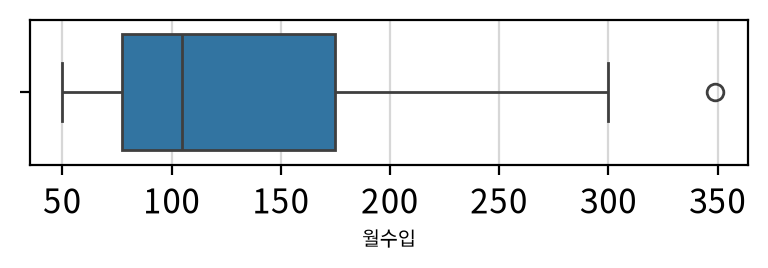

In [82]:
# 그래프 초기화
fig, ax = my_plot.init(width=400, height=150)

# 그래프 그리기
sb.boxplot(data=origin['월수입'], orient="h")
ax.set_xlabel("월수입", fontsize=7)

# 출력
my_plot.show()

> 인사이트
> - 월수입의 중앙값이 약 100~110 수준에 위치함
> - 1사분위수(Q1)는 약 80 전후, 3사분위수(Q3)는 약 170~180 전후로 보여 중간 50% 데이터 범위(IQR)가 비교적 넓음
> - 상단 수염(whisker)이 하단보다 훨씬 길어, 분포가 높은 값 방향으로 더 길게 퍼져있음
> - 약 350 부근에 상단 이상치 1개가 확인됨

2. 자동 인식 패턴에 DataFrame 지정을 위한 데이터 전처리

In [83]:
df = origin[['월수입', '나이']]
df.head()

,월수입,나이
0,60,21
1,100,22
2,200,33
3,120,33
4,70,28


3. 자동 인식 패턴에 DataFrame 지정하여 상자그림 시각화

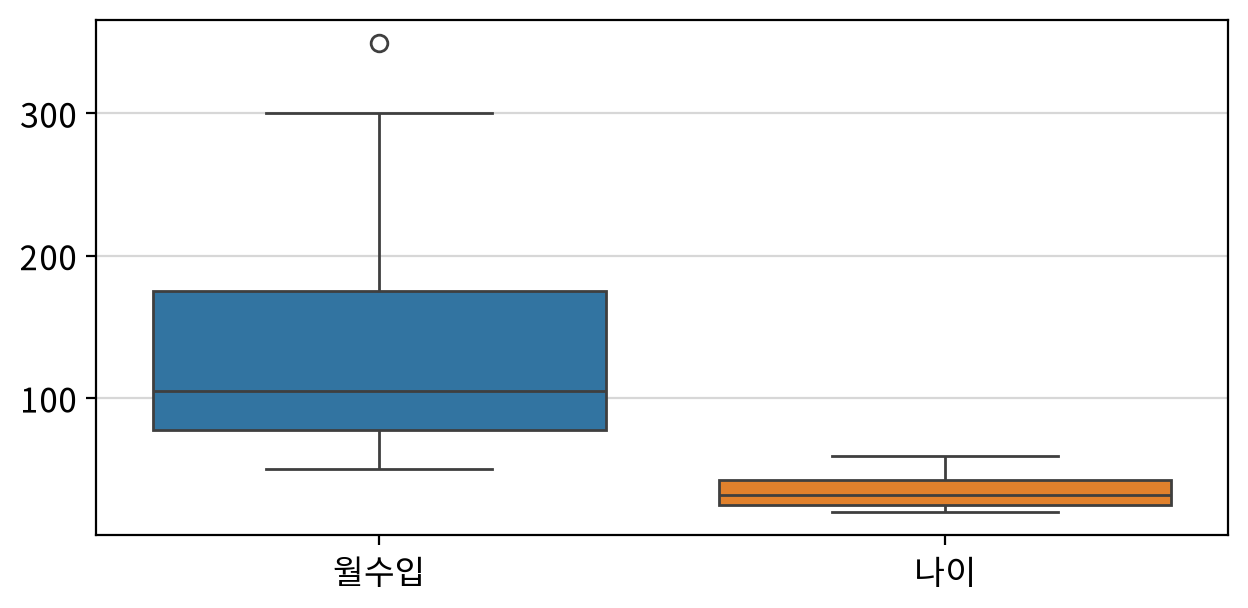

In [84]:
# 그래프 초기화
fig, ax = my_plot.init(width=640, height=320)

# 그래프 그리기
sb.boxplot(data=df, orient="v")

# 출력
my_plot.show()

> 인사이트
> - 월수입의 중앙값은 약 105 수준으로 보임
> - 월수입의 사분위 범위(IQR)는 대략 75~175 구간으로, 분산 폭이 큼
> - 월수입은 상단 수염이 약 300까지 길게 뻗고, 약 350 부근 상단 이상치 1개가 확인됨
> - 나이의 중앙값은 약 32~33 수준으로 보임
> - 나이의 사분위 범위(IQR)는 대략 25~42 구간으로, 월수입 대비 변동 폭이 좁음
> - 나이에서는 눈에 띄는 이상치가 보이지 않음
> - 동일 축에서 비교 시, 월수입이 나이보다 분포 퍼짐과 극단값 영향이 훨씬 크게 나타남

4. 개별 데이터 직접 지정 패턴

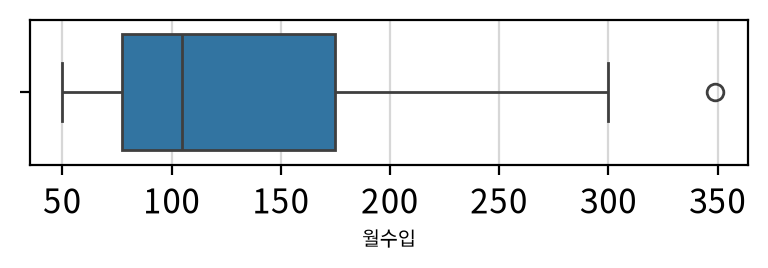

In [85]:
# 그래프 초기화
fig, ax = my_plot.init(width=400, height=150)

# 그래프 그리기
# -> 데이터가 x축으로 전개되므로 가로 방향 그래프가 된다
sb.boxplot(x=df['월수입'])
ax.set_xlabel("월수입", fontsize=7)

# 출력
my_plot.show()

5. 데이터프레임 + 컬럼명 패턴

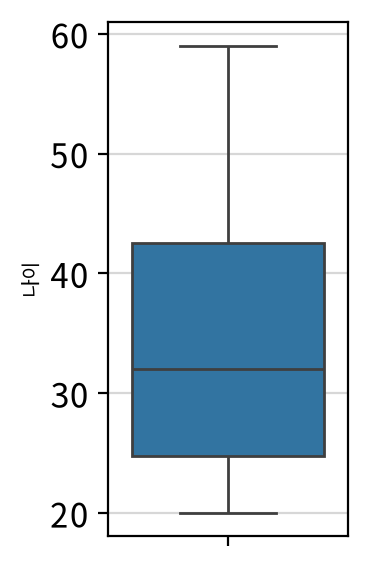

In [86]:
# 그래프 초기화
fig, ax = my_plot.init(width=200, height=300)

# 그래프 그리기
# -> 데이터가 x축으로 전개되므로 가로 방향 그래프가 된다
sb.boxplot(data=origin, y='나이')
ax.set_ylabel("나이", fontsize=7)

# 출력
my_plot.show()

> 인사이트
> - 나이의 중앙값이 약 32로 보임
> - 1사분위수(Q1)는 약 25, 3사분위수(Q3)는 약 42로 보여 중간 50%가 이 구간에 분포함
> - 최솟값은 약 20, 최댓값은 약 59로 확인됨
> - 표시된 이상치는 보이지 않음
> - 중앙값이 박스의 중앙보다 약간 아래에 있어, 상위 구간(중앙값~Q3)의 폭이 하위 구간(Q1~중앙값)보다 더 넓게 나타남

6. 범주(hue) 지정

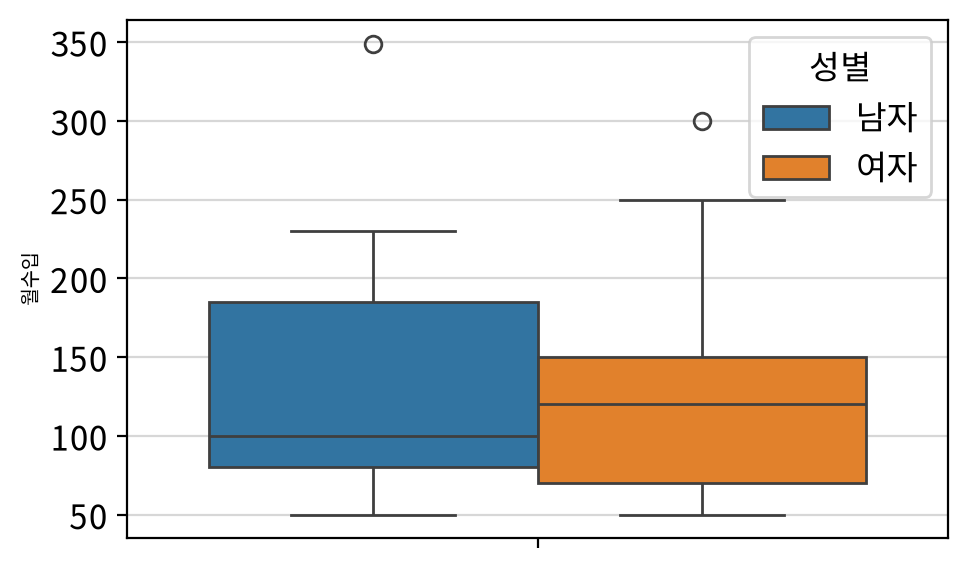

In [87]:
# 그래프 초기화
fig, ax = my_plot.init(width=500, height=300)

# 그래프 그리기
sb.boxplot(data=origin, y='월수입', hue='성별')
ax.set_ylabel("월수입", fontsize=7)

# 출력
my_plot.show()

> 인사이트
> - 성별 비교 시 중앙값은 여자(약 120)가 남자(약 100)보다 높게 나타남
> - 남자의 사분위 범위(IQR)는 대략 80~185, 여자는 대략 70~150으로 보여 남자 분포 폭이 더 넓음
> - 하한 수염은 두 집단 모두 약 50 부근으로 비슷함
> - 상한 수염은 여자(약 250)가 남자(약 230)보다 조금 더 위까지 뻗어있음
> - 두 집단 모두 상단 이상치가 보이며, 남자는 약 350, 여자는 약 300 부근에서 확인됨

### #03 모듈화 기능 확인

1. 세로 상자 그림

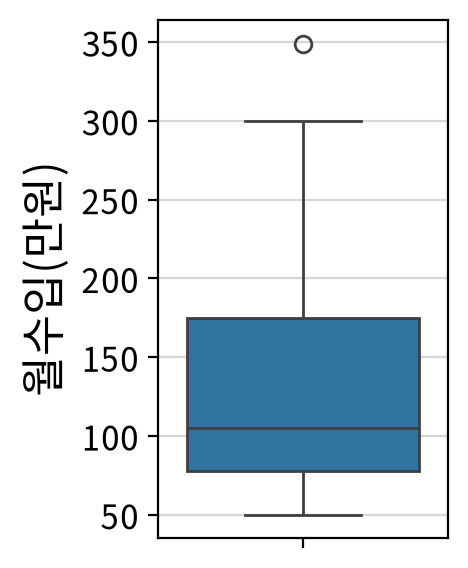

In [88]:
my_plot.boxplot(data=origin, y='월수입', ylabel="월수입(만원)",
                width=250, height=300)

2. 가로 상자 그림

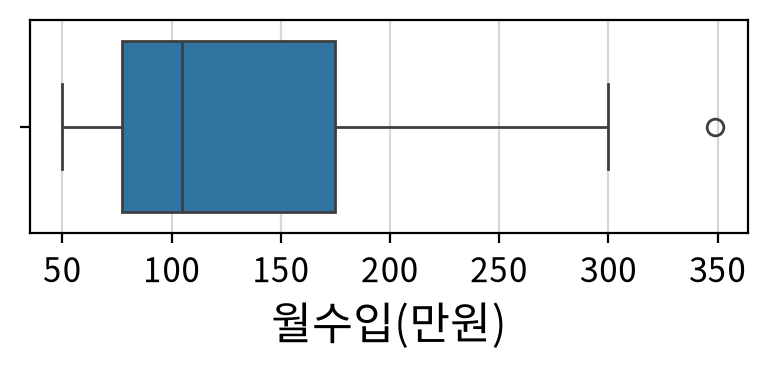

In [89]:
my_plot.boxplot(data=origin, x='월수입', xlabel="월수입(만원)",
                width=400, height=200)

3. 자동 설정 (세로 상자그림)

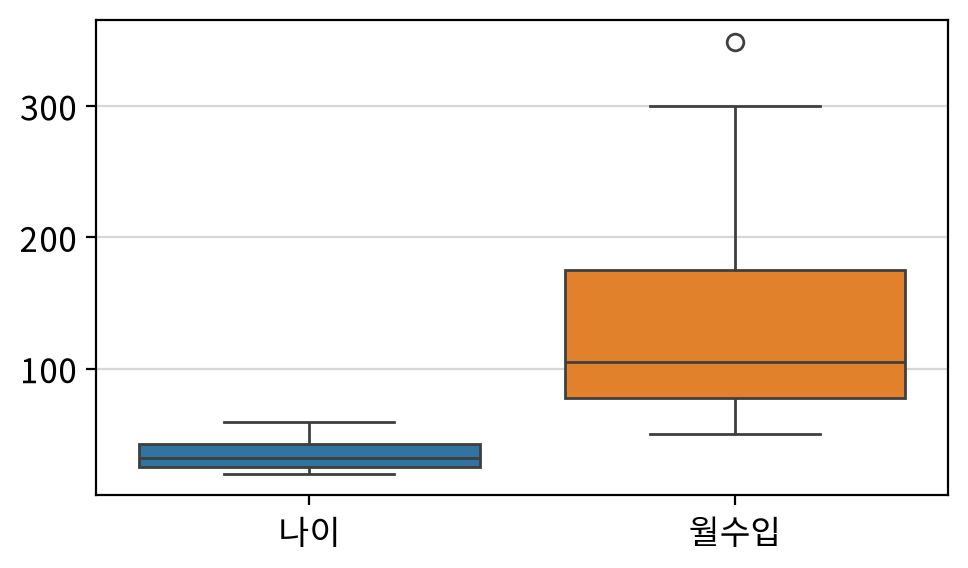

In [90]:
my_plot.boxplot(data=origin, width=500, height=300)

4. 자동 설정 (가로 상자그림)

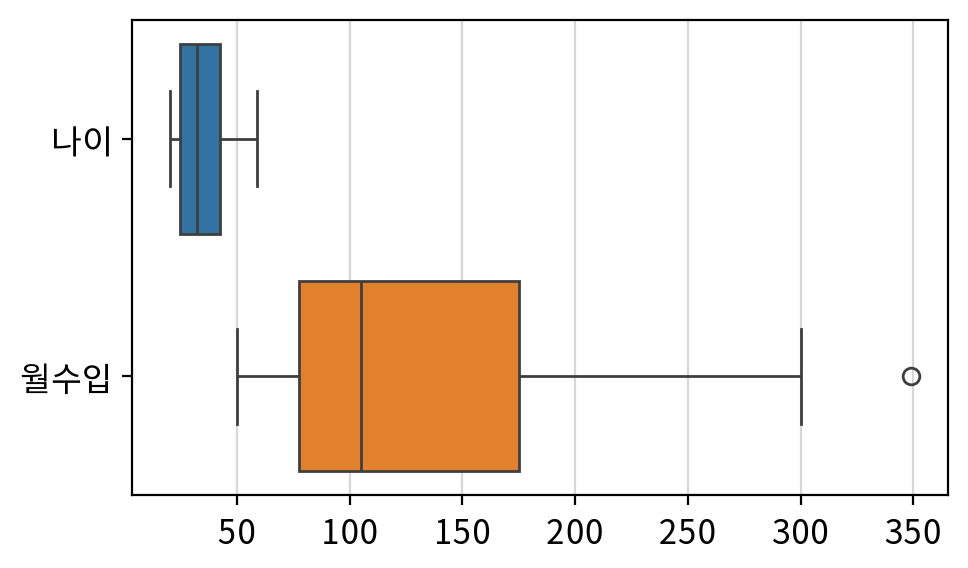

In [91]:
my_plot.boxplot(data=origin, orient="h",
                width=500, height=300)

5. 범주에 따른 구분

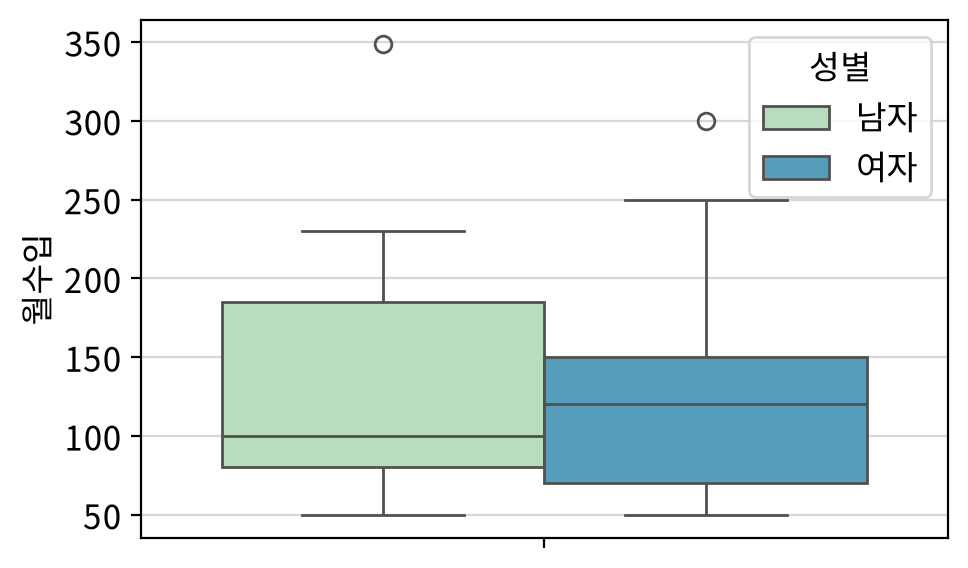

In [92]:
my_plot.boxplot(data=origin, y='월수입', hue='성별',
                width=500, height=300, palette="GnBu")

---

## 연습문제

### 1. 조선기대 역대 왕의 수명 데이터

In [93]:
# 라이브러리 참조
from jussam import load_data
from helpers import *
import seaborn as sb

In [94]:
# 데이터 가져오기
origin = load_data('kings_life')
origin.head()

📚 조선시대 역대 왕의 수명을 조사한 데이터 (출처: 방송통신대학교 통계학개론 수업내용에서 발췌)


,왕,수명
0,태조,73
1,정종,62
2,태종,45
3,세종,53
4,문종,38


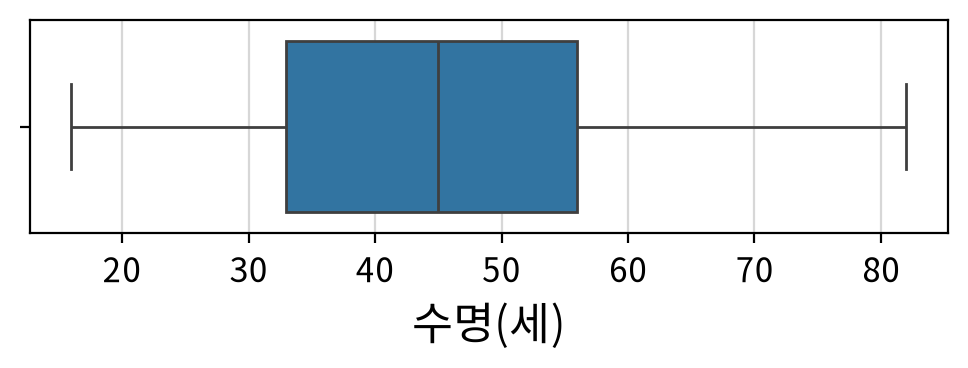

In [95]:
my_plot.boxplot(data=origin, x='수명', xlabel="수명(세)", width=500, height=200)

#### 문제 풀이 (답안)

문제 1: 상자그림(Box Plot)에서 조선시대 역대 왕들의 수명 중앙값은 약 몇 세인가?

- **정답**: 약 45세
- **해설**: 박스플롯에서 상자(box) 내부에 그려진 세로선이 중앙값(median, Q2)을 나타낸다. 시각화 결과에서 이 선은 약 45세 부근에 위치하고 있어, 조선시대 왕의 절반은 45세 이전에 사망했고 나머지 절반은 45세 이후에 사망했음을 알 수 있다.

문제 2: 상자(box)의 좌우 경계로부터 계산되는 사분위범위(IQR)는 약 얼마인가?

- **정답**: 약 23세
- **해설**: 박스의 왼쪽 경계는 1사분위수(Q1 ≈ 33세), 오른쪽 경계는 3사분위수(Q3 ≈ 56세)에 해당하며, 두 값의 차이인 IQR은 약 23세이다. 이는 조선시대 왕의 중간 50%가 약 33세에서 56세 사이의 수명을 가졌음을 의미하며, 상당수의 왕이 60세를 넘기지 못하고 비교적 이른 나이에 사망했음을 보여준다.

문제 3: 상자그림에서 수염(whisker) 바깥쪽에 표시된 점의 개수는 몇 개이며, 이를 통해 알 수 있는 사실은 무엇인가?

- **정답**: 0개 (이상치 없음)
- **해설**: 박스플롯에서 수염을 벗어난 점이 하나도 표시되지 않았으므로, 통계적 기준(Q1 - 1.5·IQR ~ Q3 + 1.5·IQR 바깥)으로 정의되는 이상치(outlier)는 존재하지 않는다. 또한 오른쪽 수염(Q3 ~ 최댓값 약 82세)이 왼쪽 수염(최솟값 약 16세 ~ Q1)보다 더 길게 나타나, 분포가 오른쪽으로 약간 치우친(우측 꼬리가 긴, positively skewed) 형태임을 함께 확인할 수 있다.


### 2. 국내외 기업의 주가 데이터

In [96]:
# 라이브러리 참조
from jussam import load_data
from helpers import *
import seaborn as sb

In [97]:
# 데이터 가져오기
origin = load_data('stock')
origin.head()

📚 상장된 금융사 중 외국기업(F)과 내국기업(K)의 주가 데이터 (출처: 방송통신대학교 통계학개론 수업내용에서 발췌)


,구분,주가
0,F,120
1,K,165
2,K,147
3,F,144
4,K,135


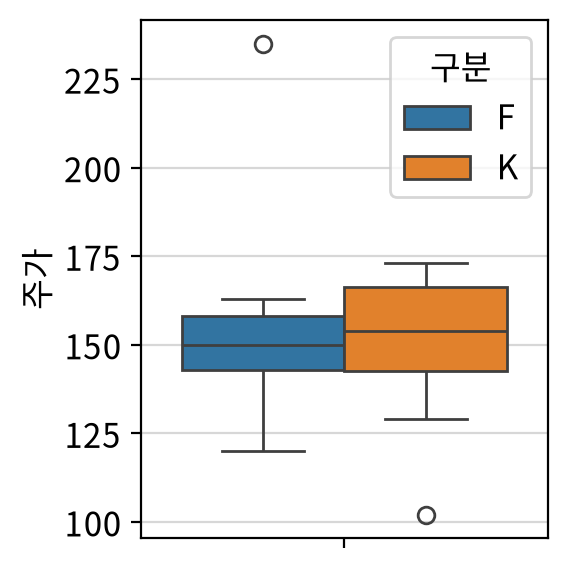

In [98]:
my_plot.boxplot(data=origin, y='주가', hue='구분',
                width=300, height=300)

> 문제 답변
> - 두 집단 중 중앙값이 더 높은 집단은 내국기업(K)이다.
>   - 박스플롯에서 각 상자(box) 내부의 가로선이 중앙값을 나타낸다. F의 중앙값은 약 150 부근, K의 중앙값은 약 154 부근에 위치하고 있어 내국기업(K)의 주가 중앙값이 외국기업(F)보다 다소 높음을 알 수 있다. 즉 절반 이상의 내국기업이 외국기업의 중앙값보다 높은 주가를 형성하고 있다.
> - 상자의 길이를 통해 알 수 있는 주가의 변동성이 더 큰 집단은 내국기업(K)이다.
>   - F의 IQR은 약 15(Q1 ≈ 143, Q3 ≈ 158), K의 IQR은 약 24(Q1 ≈ 142, Q3 ≈ 166)이다. K의 박스가 F의 박스보다 세로로 더 길게 표시되어 있어, 가운데 50%에 해당하는 데이터의 산포가 더 넓다. 따라서 내국기업(K)의 주가 변동 폭이 외국기업(F)보다 크다고 해석할 수 있다.
> - 상자그림에서 수염 바깥쪽 점으로 표시된 이상치는 총 2개이다.
>   - 외국기업(F)에는 박스 위쪽에 약 235 부근에 점으로 표시된 이상치가 1개 존재하며, 내국기업(K)에는 박스 아래쪽에 약 102 부근에 점으로 표시된 이상치가 1개 존재한다. 즉 F는 비정상적으로 주가가 높은 기업, K는 비정상적으로 주가가 낮은 기업이 각각 한 개씩 관찰되어 총 2개의 이상치가 발견된다.

### 3. 포도농장에서 수집한 비료 종류에 따른 수확량 데이터

In [99]:
# 라이브러리 참조
from jussam import load_data
from helpers import *
import seaborn as sb

In [100]:
# 데이터 가져오기
origin = load_data('grape')
origin.head()

📚 포도농장에서 수집한 비료 종류에 따른 수확량 자료 (출처: 방송통신대학교 통계학개론 수업내용에서 발췌)


,비료종류,수확량
0,A,39.300
1,B,11.400
2,A,26.600
3,A,23.700
4,B,25.800


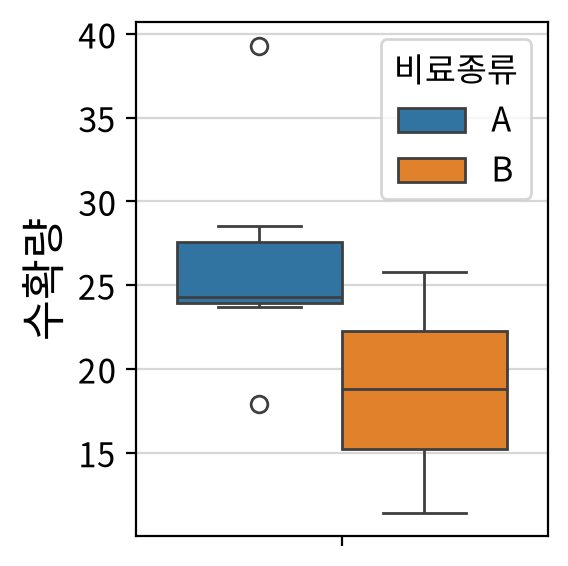

In [101]:
my_plot.boxplot(data=origin, y='수확량', ylabel="수확량", 
                hue='비료종류', width=300, height=300)

> 문제 답변
> - 두 비료 집단 중 중앙값이 더 높은 집단은 A이다.
>   - 박스플롯에서 각 상자(box) 내부의 가로선이 중앙값을 나타낸다. 비료 A의 중앙값은 약 24 부근, 비료 B의 중앙값은 약 18.5 부근에 위치하고 있어 비료 A의 수확량 중앙값이 비료 B보다 약 5 이상 높게 나타난다. 즉 평균적인 수확량 측면에서는 비료 A가 비료 B보다 우수하다고 해석할 수 있다.
> - 상자의 길이를 통해 알 수 있는 수확의 변동성이 더 큰 집단은 B이다.
>   - 비료 A의 IQR은 약 3.5(Q1 ≈ 24, Q3 ≈ 27.5), 비료 B의 IQR은 약 7(Q1 ≈ 15, Q3 ≈ 22)로 B의 박스가 A의 박스보다 약 2배 더 길게 나타난다. 따라서 비료 B는 가운데 50% 데이터의 산포가 더 넓어 수확량의 변동성이 크고, 비료 A는 비교적 일정한 수확량을 안정적으로 보이고 있음을 알 수 있다.
> - 상자그림에서 수염 바깥쪽 점으로 표시된 이상치는 총 2개이다.
>   - 비료 A에는 박스 위쪽 약 39.3 부근과 박스 아래쪽 약 17.8 부근에 각각 점으로 표시된 이상치가 1개씩, 총 2개가 존재한다. 반면 비료 B는 수염 바깥쪽에 점이 없어 이상치가 발견되지 않는다. 즉 비료 A는 대체로 안정적인 수확량을 보이지만 일부 시료에서 비정상적으로 높거나 낮은 수확량이 관찰되었음을 알 수 있다.

### 4. 통계학개론을 수강하는 두 학과의 성적 분포 데이터

In [102]:
# 라이브러리 참조
from jussam import load_data
from helpers import *
import seaborn as sb

In [103]:
# 데이터 가져오기
origin = load_data('analysis_grade')
origin.head()

📚 통계학개론을 수강하는 두 학과(A, C)의 성적분포 데이터의 일부 (출처: 방송통신대학교 통계학개론 수업내용에서 발췌)


,학과,점수
0,C,54
1,A,52
2,A,37
3,C,41
4,A,67


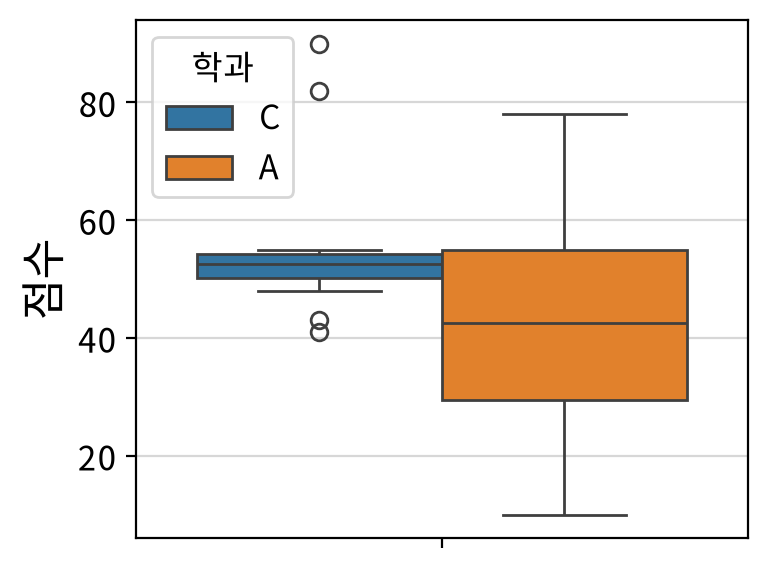

In [106]:
my_plot.boxplot(data=origin, y='점수', ylabel="점수",
                hue='학과', width=400, height=300)

> 문제 답변
> - 상자그림에서 이상치까지 포함한 전체 관측값을 기준으로, 가장 높은 점수를 받은 학생이 속한 학과는 C학과이다.
>   - 학과 A의 위쪽 수염 끝(최댓값)은 약 78점이지만, 학과 C에는 박스 위쪽에 약 90점과 약 82점에 점으로 표시된 이상치가 존재한다. 즉 학과 C의 박스/수염 자체는 좁게 형성되어 있어 일반적인 점수대는 50점대 초반에 집중되어 있지만, 예외적으로 매우 높은 점수를 받은 학생이 있어 전체 데이터에서 최고점(약 90점)은 학과 C에서 관측된다. 박스 본체만 보고 비교하면 놓치기 쉬운 인사이트이다.
> - 두 학과의 박스가 서로 공통으로 겹치는 점수 구간은 약 51 ~ 55점으로 보인다.
>   - 학과 C의 박스는 약 51~54점, 학과 A의 박스는 약 30~55점 구간에 형성되어 있다. 두 박스가 공통으로 겹치는 구간은 약 51점에서 55점 사이로, 학과 C의 박스가 거의 통째로 학과 A의 박스 상단 부근에 포함되는 형태이다. 이는 학과 C의 가운데 50%에 해당하는 학생들이 학과 A의 상위권 점수대(상위 25% 부근)와 비슷한 분포를 보임을 의미한다.
> - 학과 C의 박스 기준 위쪽 방향에는 이상치가 2개, 아래쪽 방향에서는 이상치가 2개 관측된다.
>   - 학과 C에는 박스 위쪽으로 약 82점과 약 90점 부근에 이상치가 각각 1개씩(총 2개), 박스 아래쪽으로 약 41점과 약 43점 부근에 이상치가 각각 1개씩(총 2개) 나타난다. 단순히 "이상치가 존재한다"는 사실을 넘어서, C의 이상치가 위·아래 양방향으로 균등하게 발생하고 있다는 점이 특징이며, 이는 대다수가 50점대 초중반에 밀집된 가운데 양극단의 예외적 학생들이 모두 존재함을 보여준다.